## Import


In [ ]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import warnings
from datetime import datetime

# SKLearn
from sklearn.preprocessing import MinMaxScaler
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.ensemble import RandomForestClassifier
from sklearn import metrics
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier

warnings.filterwarnings('ignore') # Ignore warnings

In [ ]:
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    precision_recall_curve,
    average_precision_score
)
import seaborn as sns
import matplotlib.pyplot as plt



In [ ]:
import random
import torch
import tensorflow as tf

np.random.seed(123)
random.seed(123)
torch.manual_seed(123)
tf.random.set_seed(123)

In [ ]:
!pip install imbalanced-learn xgboost

## Pre-Processing/EDA

In [ ]:
data = pd.read_csv('healthcare-dataset-stroke-data.csv')
data.head()

,id,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
0,9046,Male,67.0,0,1,Yes,Private,Urban,228.69,36.6,formerly smoked,1
1,51676,Female,61.0,0,0,Yes,Self-employed,Rural,202.21,NaN,never smoked,1
2,31112,Male,80.0,0,1,Yes,Private,Rural,105.92,32.5,never smoked,1
3,60182,Female,49.0,0,0,Yes,Private,Urban,171.23,34.4,smokes,1
4,1665,Female,79.0,1,0,Yes,Self-employed,Rural,174.12,24.0,never smoked,1


In [ ]:
data.drop(columns='id', inplace=True)

In [ ]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5110 entries, 0 to 5109
Data columns (total 11 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   gender             5110 non-null   object 
 1   age                5110 non-null   float64
 2   hypertension       5110 non-null   int64  
 3   heart_disease      5110 non-null   int64  
 4   ever_married       5110 non-null   object 
 5   work_type          5110 non-null   object 
 6   Residence_type     5110 non-null   object 
 7   avg_glucose_level  5110 non-null   float64
 8   bmi                4909 non-null   float64
 9   smoking_status     5110 non-null   object 
 10  stroke             5110 non-null   int64  
dtypes: float64(3), int64(3), object(5)
memory usage: 439.3+ KB


In [ ]:
round(data.describe(include='all'), 2)

,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
count,5110,5110.00,5110.0,5110.00,5110,5110,5110,5110.00,4909.00,5110,5110.00
unique,3,NaN,NaN,NaN,2,5,2,NaN,NaN,4,NaN
top,Female,NaN,NaN,NaN,Yes,Private,Urban,NaN,NaN,never smoked,NaN
freq,2994,NaN,NaN,NaN,3353,2925,2596,NaN,NaN,1892,NaN
mean,NaN,43.23,0.1,0.05,NaN,NaN,NaN,106.15,28.89,NaN,0.05
std,NaN,22.61,0.3,0.23,NaN,NaN,NaN,45.28,7.85,NaN,0.22
min,NaN,0.08,0.0,0.00,NaN,NaN,NaN,55.12,10.30,NaN,0.00
25%,NaN,25.00,0.0,0.00,NaN,NaN,NaN,77.24,23.50,NaN,0.00
50%,NaN,45.00,0.0,0.00,NaN,NaN,NaN,91.88,28.10,NaN,0.00
75%,NaN,61.00,0.0,0.00,NaN,NaN,NaN,114.09,33.10,NaN,0.00


In [ ]:
data.isna().sum()

,0
gender,0
age,0
hypertension,0
heart_disease,0
ever_married,0
work_type,0
Residence_type,0
avg_glucose_level,0
bmi,201
smoking_status,0


In [ ]:
data.bmi.replace(to_replace=np.nan, value=data.bmi.mean(), inplace=True)

In [ ]:
data.isna().sum()

,0
gender,0
age,0
hypertension,0
heart_disease,0
ever_married,0
work_type,0
Residence_type,0
avg_glucose_level,0
bmi,0
smoking_status,0


In [ ]:
data

,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
0,Male,67.0,0,1,Yes,Private,Urban,228.69,36.600000,formerly smoked,1
1,Female,61.0,0,0,Yes,Self-employed,Rural,202.21,28.893237,never smoked,1
2,Male,80.0,0,1,Yes,Private,Rural,105.92,32.500000,never smoked,1
3,Female,49.0,0,0,Yes,Private,Urban,171.23,34.400000,smokes,1
4,Female,79.0,1,0,Yes,Self-employed,Rural,174.12,24.000000,never smoked,1
...,...,...,...,...,...,...,...,...,...,...,...
5105,Female,80.0,1,0,Yes,Private,Urban,83.75,28.893237,never smoked,0
5106,Female,81.0,0,0,Yes,Self-employed,Urban,125.20,40.000000,never smoked,0
5107,Female,35.0,0,0,Yes,Self-employed,Rural,82.99,30.600000,never smoked,0
5108,Male,51.0,0,0,Yes,Private,Rural,166.29,25.600000,formerly smoked,0


In [ ]:
numeric_columns = ['age', 'bmi', 'avg_glucose_level']
categorical_columns = ['gender', 'hypertension', 'heart_disease', 'ever_married', 'work_type', 'Residence_type', 'smoking_status', 'stroke']

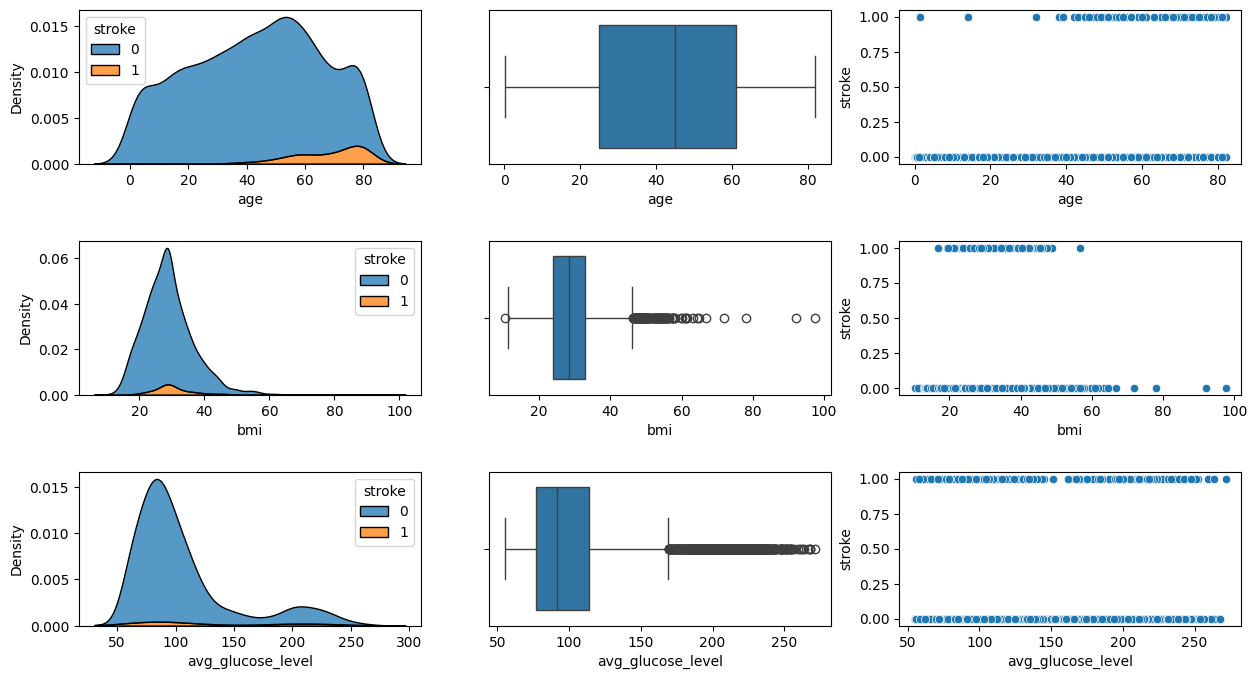

In [ ]:
i = 0
fig, ax = plt.subplots(3, 3, figsize=(15, 8))
plt.subplots_adjust(hspace = 0.5)
for num_col in numeric_columns :
    sns.kdeplot(x=num_col, hue='stroke', data=data, multiple='stack', ax=ax[i,0])
    sns.boxplot(x=num_col, data=data, ax=ax[i, 1])
    sns.scatterplot(x=num_col, y='stroke', data=data, ax=ax[i, 2])
    i+=1
plt.show()

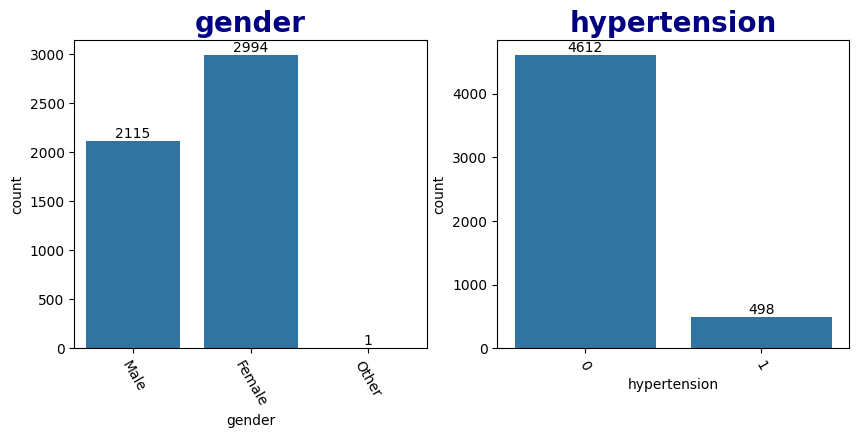

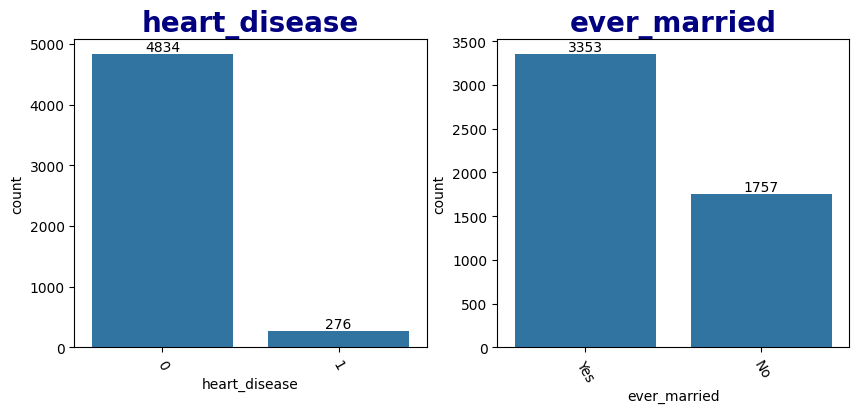

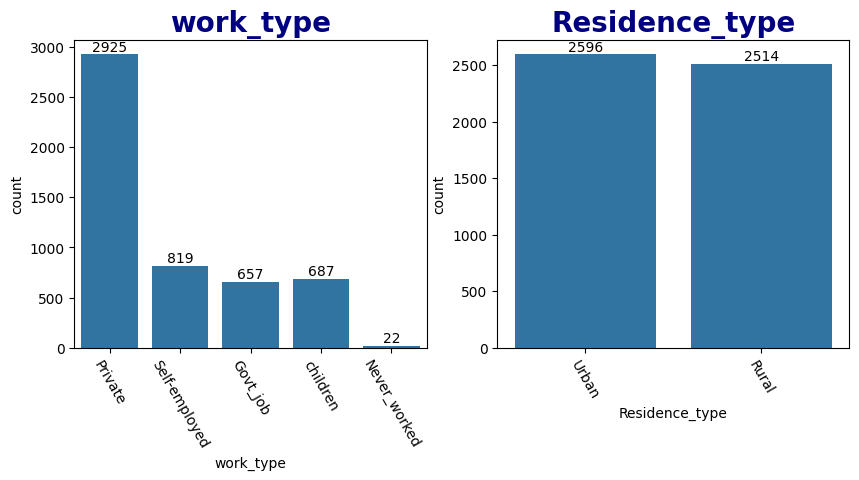

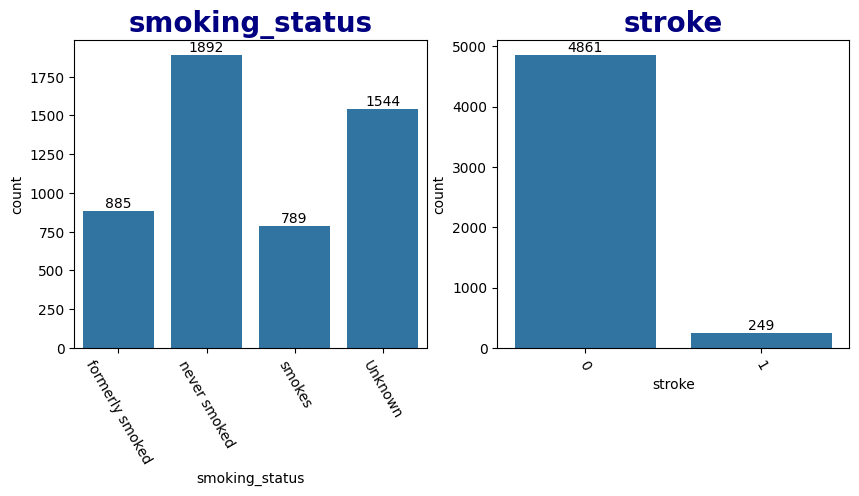

In [ ]:
i=0
while i<8 :

    # Left AX
    fig = plt.figure(figsize=(10, 4))
    plt.subplot(1, 2, 1)
    plt.title(categorical_columns[i], size=20, weight='bold', color='navy')
    ax = sns.countplot(x=categorical_columns[i], data=data)
    ax.bar_label(ax.containers[0])
    ax.tick_params(axis='x', rotation=300)
    i+=1

    # Right AX
    plt.subplot(1, 2, 2)
    plt.title(categorical_columns[i], size=20, weight='bold', color='navy')
    ax = sns.countplot(x=categorical_columns[i], data=data)
    ax.bar_label(ax.containers[0])
    ax.tick_params(axis='x', rotation=300)
    i+=1
    plt.show()

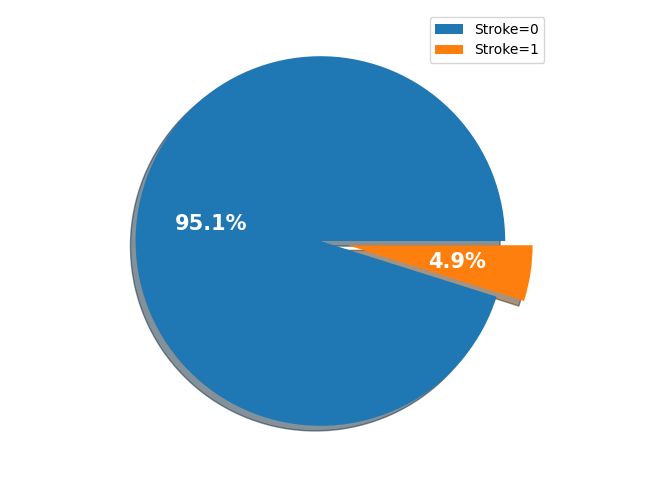

In [ ]:
x = data['stroke'].value_counts()


explode = [0, 0.15]
labels = ['Stroke=0', 'Stroke=1']
fig, ax = plt.subplots(figsize=(6, 6), subplot_kw=dict(aspect="equal"))

plt.pie(x, explode=explode, shadow=True, autopct='%1.1f%%', labels=labels, textprops=dict(color="w", weight='bold', size=15))
plt.legend()
plt.show()

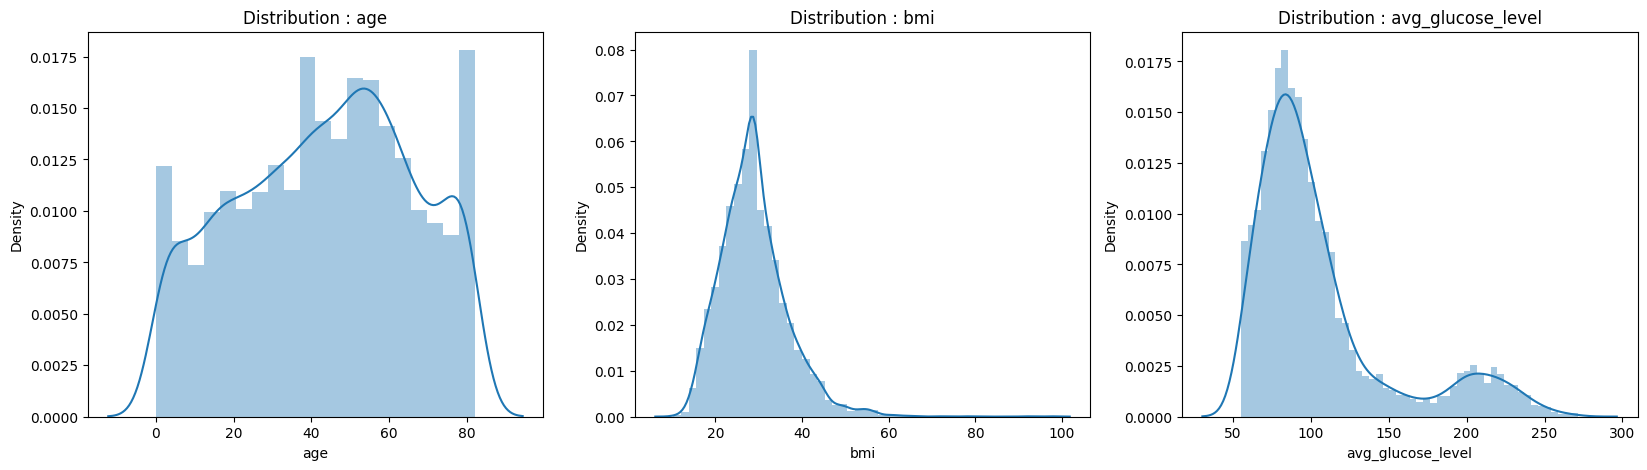

In [ ]:
fig, ax = plt.subplots(nrows = 1,ncols = 3,figsize = (20,5))
for i in range(len(numeric_columns)):
    plt.subplot(1,3,i+1)
    sns.distplot(data[numeric_columns[i]])
    title = 'Distribution : ' + numeric_columns[i]
    plt.title(title)
plt.show()

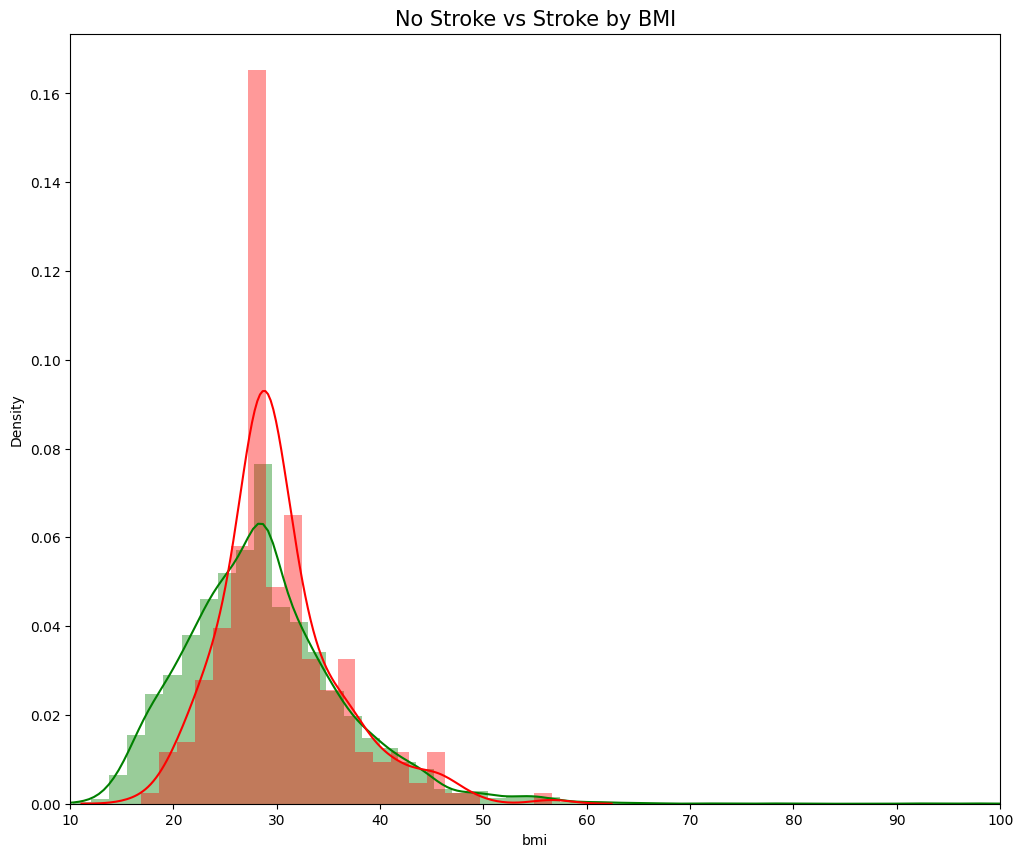

In [ ]:
plt.figure(figsize=(12,10))

sns.distplot(data[data['stroke'] == 0]["bmi"], color='green') # No Stroke - green
sns.distplot(data[data['stroke'] == 1]["bmi"], color='red') # Stroke - Red

plt.title('No Stroke vs Stroke by BMI', fontsize=15)
plt.xlim([10,100])
plt.show()

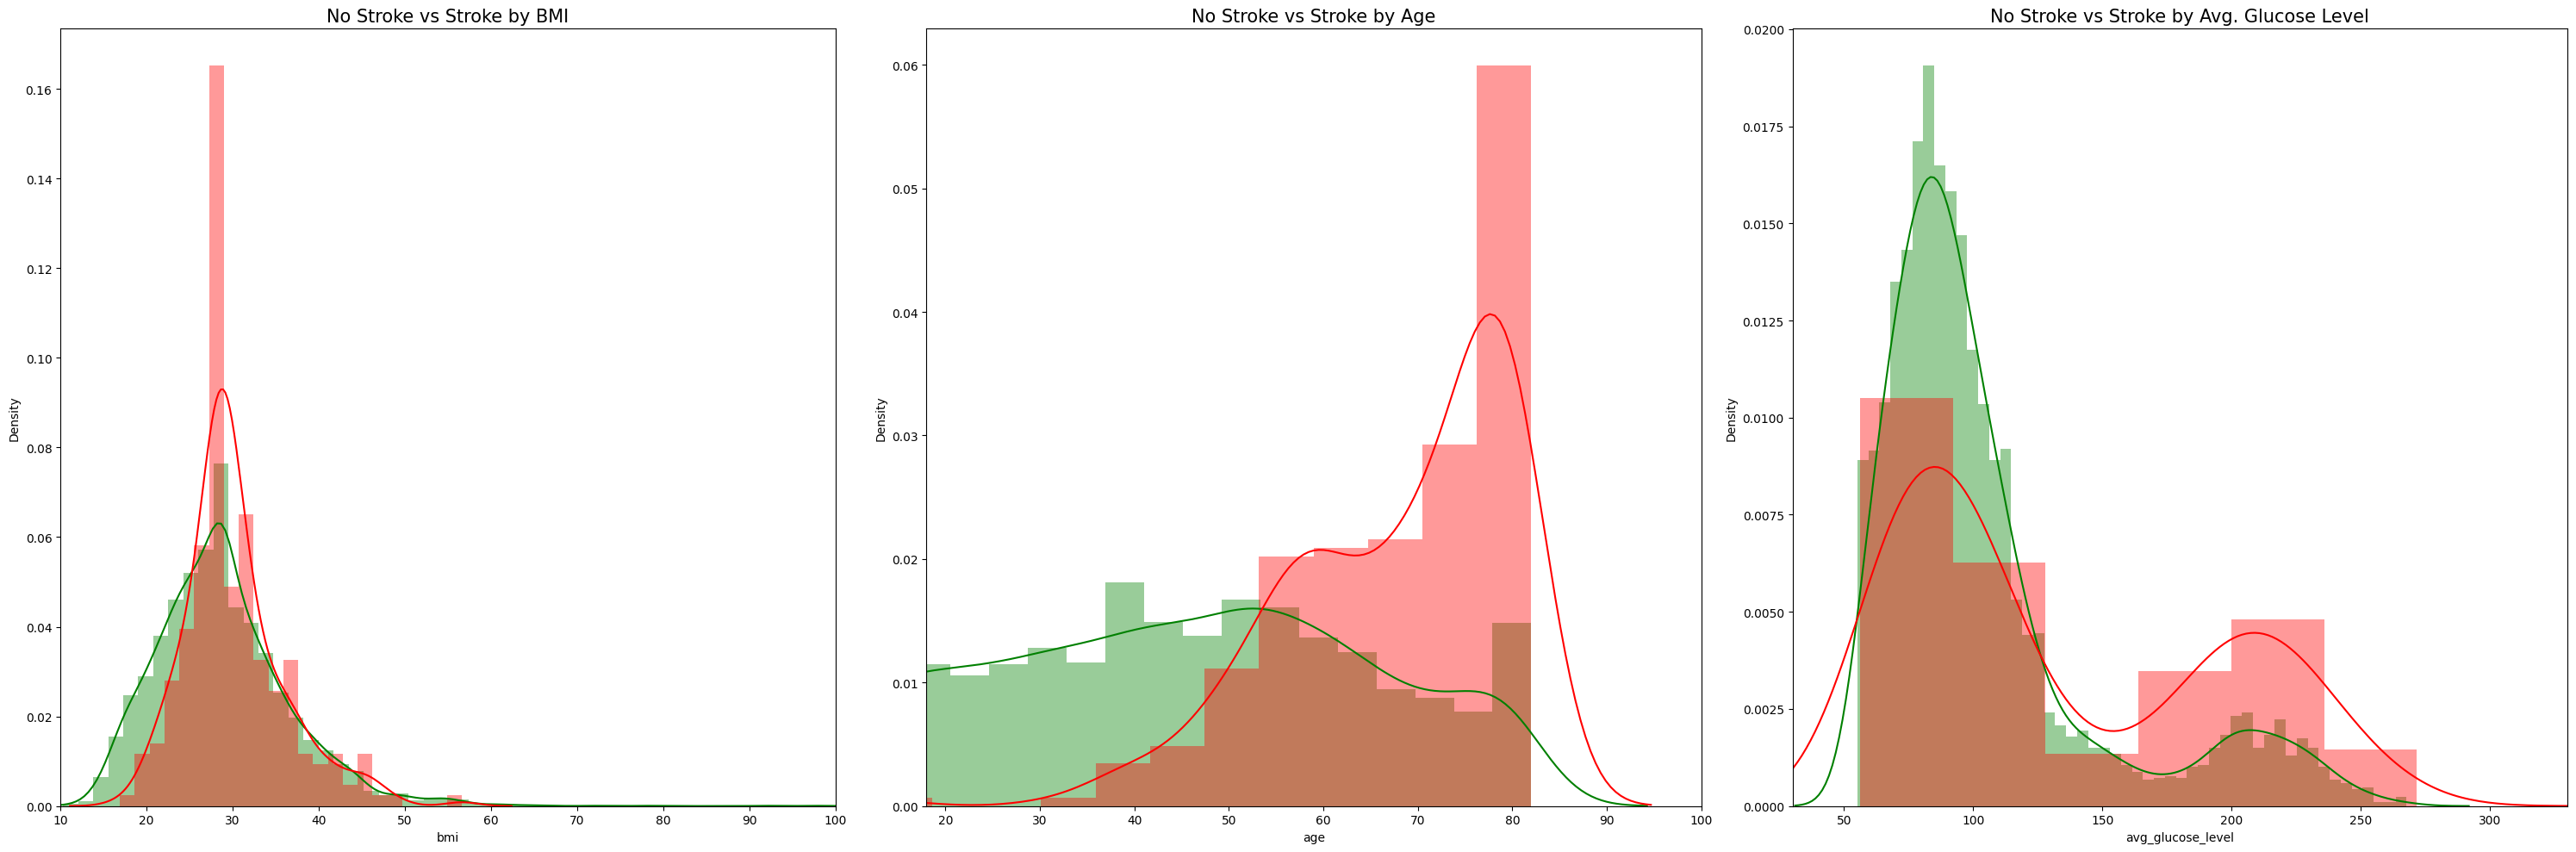

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(30, 10))

# --- Plot 1: BMI (Left) ---
sns.distplot(data[data['stroke'] == 0]["bmi"], color='green', ax=axes[0])
sns.distplot(data[data['stroke'] == 1]["bmi"], color='red', ax=axes[0])
axes[0].set_title('No Stroke vs Stroke by BMI', fontsize=15)
axes[0].set_xlim([10,100])

# --- Plot 2: Age (Middle) ---
sns.distplot(data[data['stroke'] == 0]["age"], color='green', ax=axes[1])
sns.distplot(data[data['stroke'] == 1]["age"], color='red', ax=axes[1])
axes[1].set_title('No Stroke vs Stroke by Age', fontsize=15)
axes[1].set_xlim([18,100])

# --- Plot 3: Avg Glucose Level (Right) ---
sns.distplot(data[data['stroke'] == 0]["avg_glucose_level"], color='green', ax=axes[2])
sns.distplot(data[data['stroke'] == 1]["avg_glucose_level"], color='red', ax=axes[2])
axes[2].set_title('No Stroke vs Stroke by Avg. Glucose Level', fontsize=15)
axes[2].set_xlim([30,330])

# Display the combined figure
plt.tight_layout() # Adjusts spacing so titles don't overlap
plt.show()

In [ ]:
columns_temp = ['gender', 'ever_married', 'work_type', 'smoking_status', 'Residence_type']

for col in columns_temp :
    print('column :', col)
    for index, unique in enumerate(data[col].unique()) :
        print(unique, ':', index)
    print('_'*45)

column : gender
Male : 0
Female : 1
Other : 2
_____________________________________________
column : ever_married
Yes : 0
No : 1
_____________________________________________
column : work_type
Private : 0
Self-employed : 1
Govt_job : 2
children : 3
Never_worked : 4
_____________________________________________
column : smoking_status
formerly smoked : 0
never smoked : 1
smokes : 2
Unknown : 3
_____________________________________________
column : Residence_type
Urban : 0
Rural : 1
_____________________________________________


In [ ]:
# gender
data_2 = data.replace(
    {'gender' : {'Male' : 0, 'Female' : 1, 'Other' : 2}}
)

# ever_married
data_2 =  data_2.replace(
    {'ever_married' : {'Yes' : 0, 'No' : 1}}
)

# work_type
data_2 =  data_2.replace(
    {'work_type' : {'Private' : 0, 'Self-employed' : 1, 'Govt_job' : 2, 'children' : 3, 'Never_worked' : 4}}
)

# smoking_status
data_2 =  data_2.replace(
    {'smoking_status' : {'formerly smoked' : 0, 'never smoked' : 1, 'smokes' : 2, 'Unknown' : 3}}
)

# Residence_type
data_2 =  data_2.replace(
    {'Residence_type' : {'Urban' : 0, 'Rural' : 1}}
)

In [ ]:
data_2

,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
0,0,67.0,0,1,0,0,0,228.69,36.600000,0,1
1,1,61.0,0,0,0,1,1,202.21,28.893237,1,1
2,0,80.0,0,1,0,0,1,105.92,32.500000,1,1
3,1,49.0,0,0,0,0,0,171.23,34.400000,2,1
4,1,79.0,1,0,0,1,1,174.12,24.000000,1,1
...,...,...,...,...,...,...,...,...,...,...,...
5105,1,80.0,1,0,0,0,0,83.75,28.893237,1,0
5106,1,81.0,0,0,0,1,0,125.20,40.000000,1,0
5107,1,35.0,0,0,0,1,1,82.99,30.600000,1,0
5108,0,51.0,0,0,0,0,1,166.29,25.600000,0,0


## Splitting & Resampling

In [ ]:
X_temp = data_2.drop(columns='stroke')
y = data_2.stroke

In [ ]:
from imblearn.over_sampling import SMOTE
from imblearn.combine import SMOTEENN

from xgboost import XGBClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    classification_report
)

In [ ]:
# Train-test split (stratified karena data imbalanced)
X_train, X_test, y_train, y_test = train_test_split(
    X_temp, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Scaling (MinMaxScaler yang sudah kamu import di awal)
scaler = MinMaxScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled  = scaler.transform(X_test)


In [ ]:
print("Number transactions x_train dataset: ", X_train.shape)
print("Number transactions y_train dataset: ", y_train.shape)
print("Number transactions x_test dataset: ", X_test.shape)
print("Number transactions y_test dataset: ", y_test.shape)

Number transactions x_train dataset:  (4088, 10)
Number transactions y_train dataset:  (4088,)
Number transactions x_test dataset:  (1022, 10)
Number transactions y_test dataset:  (1022,)


In [ ]:
# 3.1. Baseline
X_train_orig = X_train_scaled
y_train_orig = y_train

# 3.2. SMOTE
smote = SMOTE(random_state=42)
X_train_smote, y_train_smote = smote.fit_resample(X_train_scaled, y_train)

# 3.3. SMOTE-ENN
smote_enn = SMOTEENN(random_state=42)
X_train_smoteenn, y_train_smoteenn = smote_enn.fit_resample(X_train_scaled, y_train)

print("Original:", np.bincount(y_train_orig))
print("SMOTE   :", np.bincount(y_train_smote))
print("SMOTE-ENN:", np.bincount(y_train_smoteenn))


Original: [3889  199]
SMOTE   : [3889 3889]
SMOTE-ENN: [3148 3618]


## Modelling LR, SVM, XGB



In [ ]:
results_list = []

=== Logistic Regression — ORIGINAL ===
              precision    recall  f1-score   support

           0       0.95      1.00      0.97       972
           1       0.00      0.00      0.00        50

    accuracy                           0.95      1022
   macro avg       0.48      0.50      0.49      1022
weighted avg       0.90      0.95      0.93      1022

Accuracy : 0.9510763209393346
Precision: 0.0
Recall   : 0.0
F1-score : 0.0
PR-AUC   : 0.25712899525218086


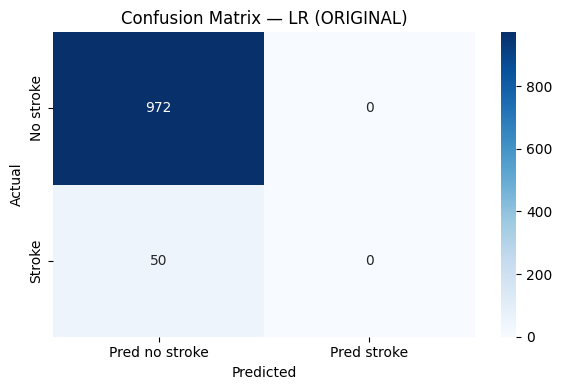

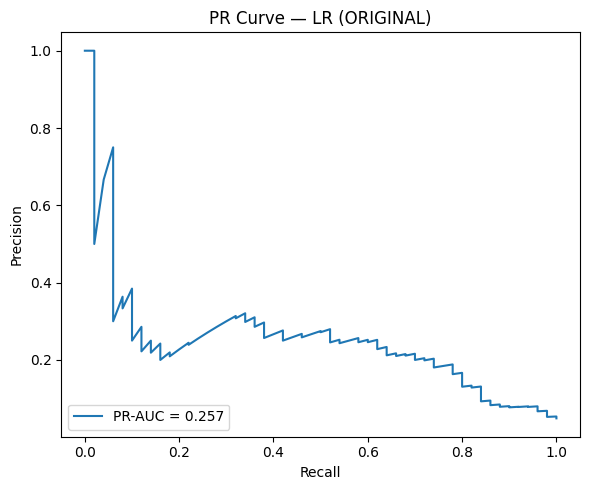

In [ ]:
# Logistic Regression — ORIGINAL
lr_model = LogisticRegression(max_iter=1000, random_state=42)

lr_model.fit(X_train_orig, y_train_orig)

y_pred = lr_model.predict(X_test_scaled)
y_score = lr_model.predict_proba(X_test_scaled)[:, 1]

print("=== Logistic Regression — ORIGINAL ===")
print(classification_report(y_test, y_pred))

acc    = accuracy_score(y_test, y_pred)
prec   = precision_score(y_test, y_pred, zero_division=0)
rec    = recall_score(y_test, y_pred, zero_division=0)
f1     = f1_score(y_test, y_pred, zero_division=0)
pr_auc = average_precision_score(y_test, y_score)

print("Accuracy :", acc)
print("Precision:", prec)
print("Recall   :", rec)
print("F1-score :", f1)
print("PR-AUC   :", pr_auc)

# Confusion matrix
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(6,4))
sns.heatmap(cm, annot=True, cmap="Blues", fmt="d",
            yticklabels=['No stroke', 'Stroke'],
            xticklabels=['Pred no stroke', 'Pred stroke'])
plt.title("Confusion Matrix — LR (ORIGINAL)")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.tight_layout()
plt.show()

# PR Curve
precision_curve, recall_curve, thresholds = precision_recall_curve(y_test, y_score)
plt.figure(figsize=(6,5))
plt.plot(recall_curve, precision_curve, label=f"PR-AUC = {pr_auc:.3f}")
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("PR Curve — LR (ORIGINAL)")
plt.legend(loc="lower left")
plt.tight_layout()
plt.show()

# Save for final comparison table
results_list.append(["LR", "Original", acc, prec, rec, f1, pr_auc])

=== Logistic Regression — SMOTE ===
              precision    recall  f1-score   support

           0       0.99      0.76      0.86       972
           1       0.14      0.78      0.24        50

    accuracy                           0.76      1022
   macro avg       0.56      0.77      0.55      1022
weighted avg       0.94      0.76      0.83      1022

Accuracy : 0.7573385518590998
Precision: 0.14130434782608695
Recall   : 0.78
F1-score : 0.2392638036809816
PR-AUC   : 0.2657595734173849


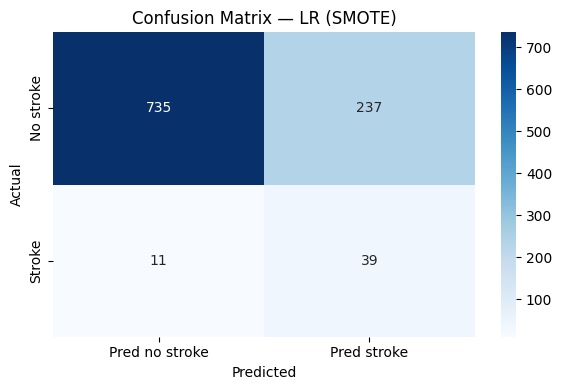

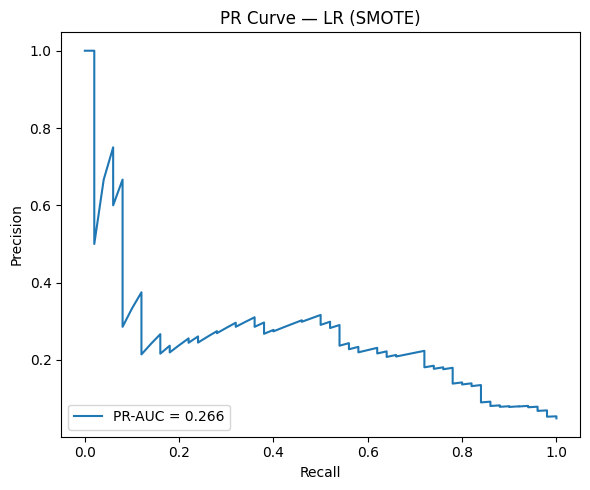

In [ ]:
# Logistic Regression — SMOTE
lr_model = LogisticRegression(max_iter=1000, random_state=42, class_weight="balanced")

lr_model.fit(X_train_smote, y_train_smote)

y_pred = lr_model.predict(X_test_scaled)
y_score = lr_model.predict_proba(X_test_scaled)[:, 1]

print("=== Logistic Regression — SMOTE ===")
print(classification_report(y_test, y_pred))

acc    = accuracy_score(y_test, y_pred)
prec   = precision_score(y_test, y_pred, zero_division=0)
rec    = recall_score(y_test, y_pred, zero_division=0)
f1     = f1_score(y_test, y_pred, zero_division=0)
pr_auc = average_precision_score(y_test, y_score)

print("Accuracy :", acc)
print("Precision:", prec)
print("Recall   :", rec)
print("F1-score :", f1)
print("PR-AUC   :", pr_auc)

cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(6,4))
sns.heatmap(cm, annot=True, cmap="Blues", fmt="d",
            yticklabels=['No stroke', 'Stroke'],
            xticklabels=['Pred no stroke', 'Pred stroke'])
plt.title("Confusion Matrix — LR (SMOTE)")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.tight_layout()
plt.show()

precision_curve, recall_curve, thresholds = precision_recall_curve(y_test, y_score)
plt.figure(figsize=(6,5))
plt.plot(recall_curve, precision_curve, label=f"PR-AUC = {pr_auc:.3f}")
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("PR Curve — LR (SMOTE)")
plt.legend(loc="lower left")
plt.tight_layout()
plt.show()

results_list.append(["LR", "SMOTE", acc, prec, rec, f1, pr_auc])

=== Logistic Regression — SMOTE-ENN ===
              precision    recall  f1-score   support

           0       0.99      0.71      0.83       972
           1       0.13      0.82      0.22        50

    accuracy                           0.72      1022
   macro avg       0.56      0.77      0.52      1022
weighted avg       0.95      0.72      0.80      1022

Accuracy : 0.7172211350293543
Precision: 0.1277258566978193
Recall   : 0.82
F1-score : 0.2210242587601078
PR-AUC   : 0.259408682473


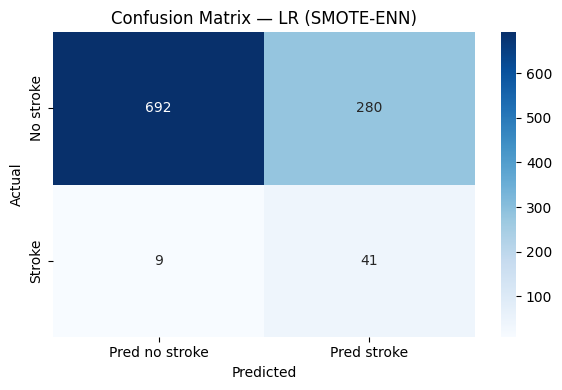

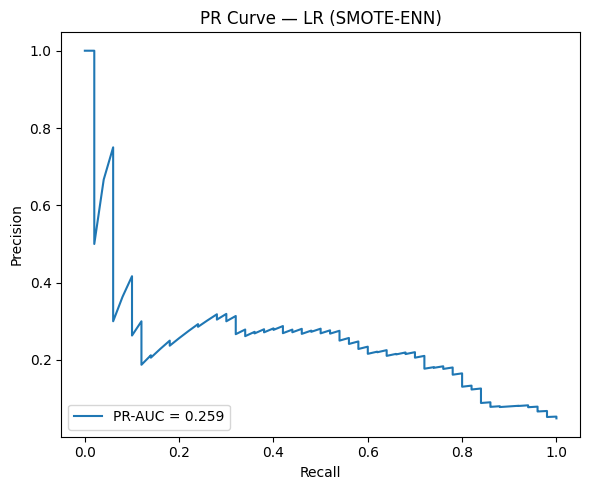

In [ ]:
# Logistic Regression — SMOTE-ENN
lr_model = LogisticRegression(max_iter=1000, random_state=42)

lr_model.fit(X_train_smoteenn, y_train_smoteenn)

y_pred = lr_model.predict(X_test_scaled)
y_score = lr_model.predict_proba(X_test_scaled)[:, 1]

print("=== Logistic Regression — SMOTE-ENN ===")
print(classification_report(y_test, y_pred))

acc    = accuracy_score(y_test, y_pred)
prec   = precision_score(y_test, y_pred, zero_division=0)
rec    = recall_score(y_test, y_pred, zero_division=0)
f1     = f1_score(y_test, y_pred, zero_division=0)
pr_auc = average_precision_score(y_test, y_score)

print("Accuracy :", acc)
print("Precision:", prec)
print("Recall   :", rec)
print("F1-score :", f1)
print("PR-AUC   :", pr_auc)

cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(6,4))
sns.heatmap(cm, annot=True, cmap="Blues", fmt="d",
            yticklabels=['No stroke', 'Stroke'],
            xticklabels=['Pred no stroke', 'Pred stroke'])
plt.title("Confusion Matrix — LR (SMOTE-ENN)")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.tight_layout()
plt.show()

precision_curve, recall_curve, thresholds = precision_recall_curve(y_test, y_score)
plt.figure(figsize=(6,5))
plt.plot(recall_curve, precision_curve, label=f"PR-AUC = {pr_auc:.3f}")
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("PR Curve — LR (SMOTE-ENN)")
plt.legend(loc="lower left")
plt.tight_layout()
plt.show()

results_list.append(["LR", "SMOTE-ENN", acc, prec, rec, f1, pr_auc])

=== SVM RBF — ORIGINAL ===
              precision    recall  f1-score   support

           0       0.95      1.00      0.97       972
           1       0.00      0.00      0.00        50

    accuracy                           0.95      1022
   macro avg       0.48      0.50      0.49      1022
weighted avg       0.90      0.95      0.93      1022

Accuracy : 0.9510763209393346
Precision: 0.0
Recall   : 0.0
F1-score : 0.0
PR-AUC   : 0.0957952832133846


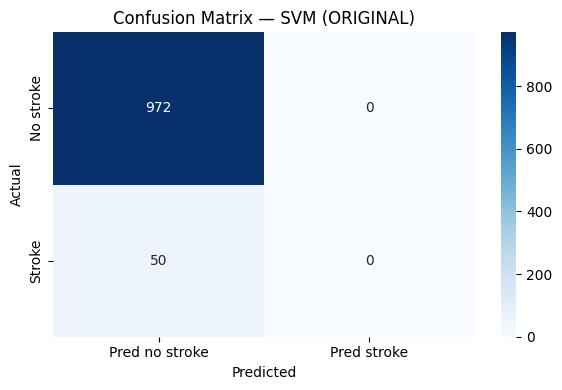

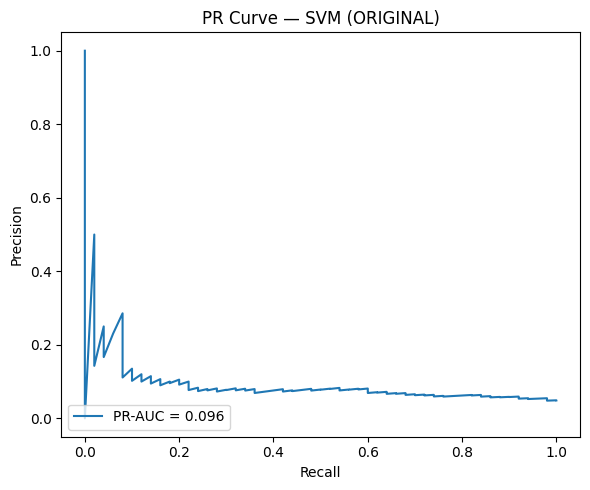

In [ ]:
# SVM RBF — ORIGINAL
svm_model = SVC(kernel="rbf", probability=True, random_state=42)

svm_model.fit(X_train_orig, y_train_orig)

y_pred = svm_model.predict(X_test_scaled)
y_score = svm_model.predict_proba(X_test_scaled)[:, 1]

print("=== SVM RBF — ORIGINAL ===")
print(classification_report(y_test, y_pred))

acc    = accuracy_score(y_test, y_pred)
prec   = precision_score(y_test, y_pred, zero_division=0)
rec    = recall_score(y_test, y_pred, zero_division=0)
f1     = f1_score(y_test, y_pred, zero_division=0)
pr_auc = average_precision_score(y_test, y_score)

print("Accuracy :", acc)
print("Precision:", prec)
print("Recall   :", rec)
print("F1-score :", f1)
print("PR-AUC   :", pr_auc)

cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(6,4))
sns.heatmap(cm, annot=True, cmap="Blues", fmt="d",
            yticklabels=['No stroke', 'Stroke'],
            xticklabels=['Pred no stroke', 'Pred stroke'])
plt.title("Confusion Matrix — SVM (ORIGINAL)")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.tight_layout()
plt.show()

precision_curve, recall_curve, thresholds = precision_recall_curve(y_test, y_score)
plt.figure(figsize=(6,5))
plt.plot(recall_curve, precision_curve, label=f"PR-AUC = {pr_auc:.3f}")
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("PR Curve — SVM (ORIGINAL)")
plt.legend(loc="lower left")
plt.tight_layout()
plt.show()

results_list.append(["SVM", "Original", acc, prec, rec, f1, pr_auc])

=== SVM RBF — SMOTE ===
              precision    recall  f1-score   support

           0       0.98      0.76      0.85       972
           1       0.13      0.74      0.23        50

    accuracy                           0.75      1022
   macro avg       0.56      0.75      0.54      1022
weighted avg       0.94      0.75      0.82      1022

Accuracy : 0.7544031311154599
Precision: 0.13454545454545455
Recall   : 0.74
F1-score : 0.2276923076923077
PR-AUC   : 0.21196024696495364


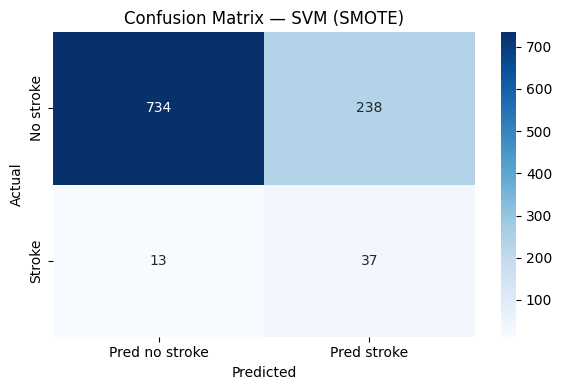

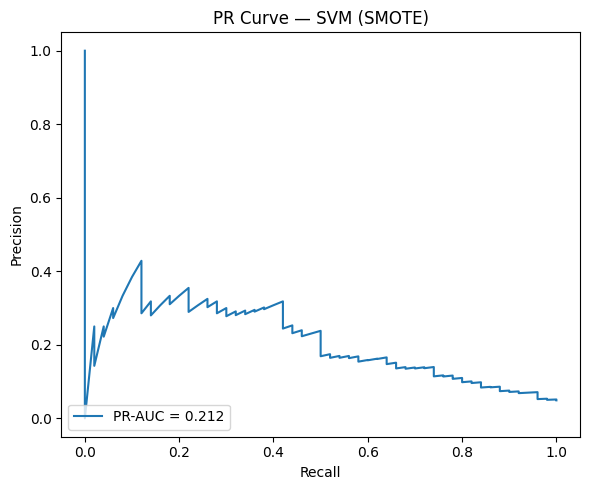

In [ ]:
# SVM RBF — SMOTE
svm_model = SVC(kernel="rbf", probability=True, random_state=42)

svm_model.fit(X_train_smote, y_train_smote)

y_pred = svm_model.predict(X_test_scaled)
y_score = svm_model.predict_proba(X_test_scaled)[:, 1]

print("=== SVM RBF — SMOTE ===")
print(classification_report(y_test, y_pred))

acc    = accuracy_score(y_test, y_pred)
prec   = precision_score(y_test, y_pred, zero_division=0)
rec    = recall_score(y_test, y_pred, zero_division=0)
f1     = f1_score(y_test, y_pred, zero_division=0)
pr_auc = average_precision_score(y_test, y_score)

print("Accuracy :", acc)
print("Precision:", prec)
print("Recall   :", rec)
print("F1-score :", f1)
print("PR-AUC   :", pr_auc)

cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(6,4))
sns.heatmap(cm, annot=True, cmap="Blues", fmt="d",
            yticklabels=['No stroke', 'Stroke'],
            xticklabels=['Pred no stroke', 'Pred stroke'])
plt.title("Confusion Matrix — SVM (SMOTE)")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.tight_layout()
plt.show()

precision_curve, recall_curve, thresholds = precision_recall_curve(y_test, y_score)
plt.figure(figsize=(6,5))
plt.plot(recall_curve, precision_curve, label=f"PR-AUC = {pr_auc:.3f}")
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("PR Curve — SVM (SMOTE)")
plt.legend(loc="lower left")
plt.tight_layout()
plt.show()

results_list.append(["SVM", "SMOTE", acc, prec, rec, f1, pr_auc])


=== SVM RBF — SMOTE-ENN ===
              precision    recall  f1-score   support

           0       0.98      0.71      0.83       972
           1       0.12      0.78      0.21        50

    accuracy                           0.72      1022
   macro avg       0.55      0.75      0.52      1022
weighted avg       0.94      0.72      0.80      1022

Accuracy : 0.7152641878669276
Precision: 0.12225705329153605
Recall   : 0.78
F1-score : 0.21138211382113822
PR-AUC   : 0.20705318377798473


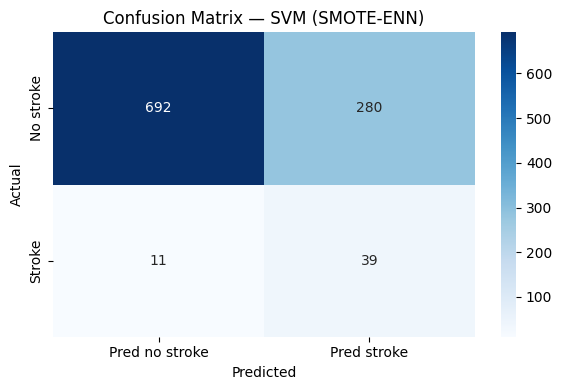

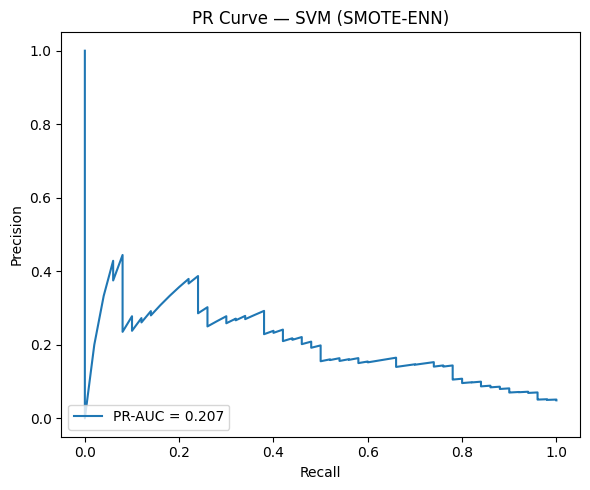

In [ ]:
# SVM RBF — SMOTE-ENN
svm_model = SVC(kernel="rbf", probability=True, random_state=42)

svm_model.fit(X_train_smoteenn, y_train_smoteenn)

y_pred = svm_model.predict(X_test_scaled)
y_score = svm_model.predict_proba(X_test_scaled)[:, 1]

print("=== SVM RBF — SMOTE-ENN ===")
print(classification_report(y_test, y_pred))

acc    = accuracy_score(y_test, y_pred)
prec   = precision_score(y_test, y_pred, zero_division=0)
rec    = recall_score(y_test, y_pred, zero_division=0)
f1     = f1_score(y_test, y_pred, zero_division=0)
pr_auc = average_precision_score(y_test, y_score)

print("Accuracy :", acc)
print("Precision:", prec)
print("Recall   :", rec)
print("F1-score :", f1)
print("PR-AUC   :", pr_auc)

cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(6,4))
sns.heatmap(cm, annot=True, cmap="Blues", fmt="d",
            yticklabels=['No stroke', 'Stroke'],
            xticklabels=['Pred no stroke', 'Pred stroke'])
plt.title("Confusion Matrix — SVM (SMOTE-ENN)")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.tight_layout()
plt.show()

precision_curve, recall_curve, thresholds = precision_recall_curve(y_test, y_score)
plt.figure(figsize=(6,5))
plt.plot(recall_curve, precision_curve, label=f"PR-AUC = {pr_auc:.3f}")
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("PR Curve — SVM (SMOTE-ENN)")
plt.legend(loc="lower left")
plt.tight_layout()
plt.show()

results_list.append(["SVM", "SMOTE-ENN", acc, prec, rec, f1, pr_auc])


=== XGBoost — ORIGINAL ===
              precision    recall  f1-score   support

           0       0.95      1.00      0.97       972
           1       0.50      0.04      0.07        50

    accuracy                           0.95      1022
   macro avg       0.73      0.52      0.52      1022
weighted avg       0.93      0.95      0.93      1022

Accuracy : 0.9510763209393346
Precision: 0.5
Recall   : 0.04
F1-score : 0.07407407407407407
PR-AUC   : 0.20730646662671515


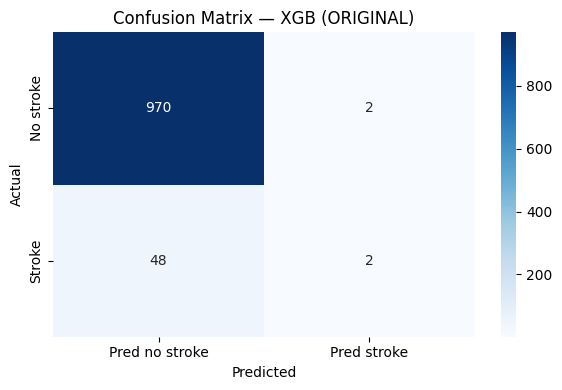

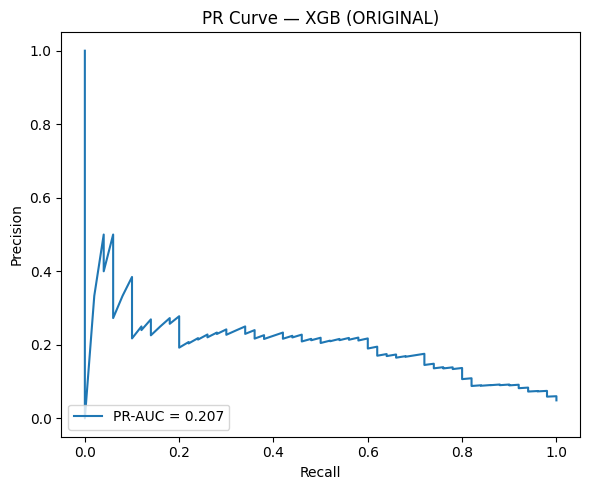

In [ ]:
# XGBoost — ORIGINAL
xgb_model = XGBClassifier(
    n_estimators=200,
    learning_rate=0.05,
    max_depth=4,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="binary:logistic",
    eval_metric="logloss",
    n_jobs=-1,
    random_state=42
)

xgb_model.fit(X_train_orig, y_train_orig)

y_pred = xgb_model.predict(X_test_scaled)
y_score = xgb_model.predict_proba(X_test_scaled)[:, 1]

print("=== XGBoost — ORIGINAL ===")
print(classification_report(y_test, y_pred))

acc    = accuracy_score(y_test, y_pred)
prec   = precision_score(y_test, y_pred, zero_division=0)
rec    = recall_score(y_test, y_pred, zero_division=0)
f1     = f1_score(y_test, y_pred, zero_division=0)
pr_auc = average_precision_score(y_test, y_score)

print("Accuracy :", acc)
print("Precision:", prec)
print("Recall   :", rec)
print("F1-score :", f1)
print("PR-AUC   :", pr_auc)

cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(6,4))
sns.heatmap(cm, annot=True, cmap="Blues", fmt="d",
            yticklabels=['No stroke', 'Stroke'],
            xticklabels=['Pred no stroke', 'Pred stroke'])
plt.title("Confusion Matrix — XGB (ORIGINAL)")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.tight_layout()
plt.show()

precision_curve, recall_curve, thresholds = precision_recall_curve(y_test, y_score)
plt.figure(figsize=(6,5))
plt.plot(recall_curve, precision_curve, label=f"PR-AUC = {pr_auc:.3f}")
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("PR Curve — XGB (ORIGINAL)")
plt.legend(loc="lower left")
plt.tight_layout()
plt.show()

results_list.append(["XGB", "Original", acc, prec, rec, f1, pr_auc])


=== XGBoost — SMOTE ===
              precision    recall  f1-score   support

           0       0.97      0.91      0.94       972
           1       0.22      0.50      0.31        50

    accuracy                           0.89      1022
   macro avg       0.60      0.70      0.62      1022
weighted avg       0.94      0.89      0.91      1022

Accuracy : 0.8894324853228963
Precision: 0.22123893805309736
Recall   : 0.5
F1-score : 0.3067484662576687
PR-AUC   : 0.19875930952616022


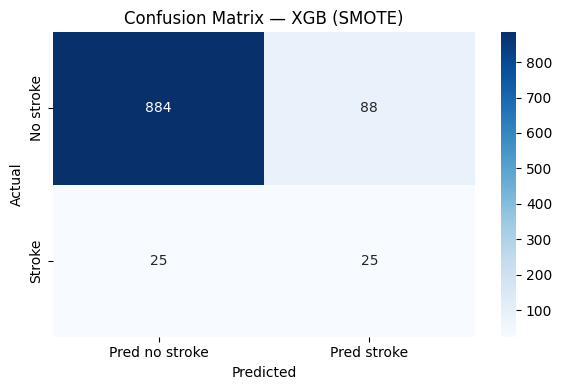

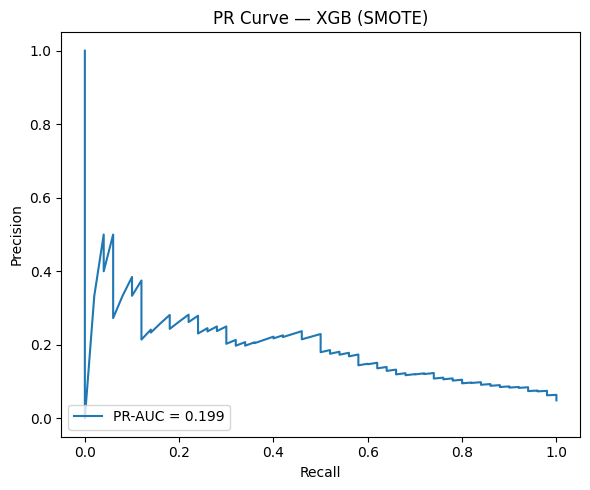

In [ ]:
# XGBoost — SMOTE
xgb_model = XGBClassifier(
    n_estimators=200,
    learning_rate=0.05,
    max_depth=4,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="binary:logistic",
    eval_metric="logloss",
    n_jobs=-1,
    random_state=42
)

xgb_model.fit(X_train_smote, y_train_smote)

y_pred = xgb_model.predict(X_test_scaled)
y_score = xgb_model.predict_proba(X_test_scaled)[:, 1]

print("=== XGBoost — SMOTE ===")
print(classification_report(y_test, y_pred))

acc    = accuracy_score(y_test, y_pred)
prec   = precision_score(y_test, y_pred, zero_division=0)
rec    = recall_score(y_test, y_pred, zero_division=0)
f1     = f1_score(y_test, y_pred, zero_division=0)
pr_auc = average_precision_score(y_test, y_score)

print("Accuracy :", acc)
print("Precision:", prec)
print("Recall   :", rec)
print("F1-score :", f1)
print("PR-AUC   :", pr_auc)

cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(6,4))
sns.heatmap(cm, annot=True, cmap="Blues", fmt="d",
            yticklabels=['No stroke', 'Stroke'],
            xticklabels=['Pred no stroke', 'Pred stroke'])
plt.title("Confusion Matrix — XGB (SMOTE)")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.tight_layout()
plt.show()

precision_curve, recall_curve, thresholds = precision_recall_curve(y_test, y_score)
plt.figure(figsize=(6,5))
plt.plot(recall_curve, precision_curve, label=f"PR-AUC = {pr_auc:.3f}")
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("PR Curve — XGB (SMOTE)")
plt.legend(loc="lower left")
plt.tight_layout()
plt.show()

results_list.append(["XGB", "SMOTE", acc, prec, rec, f1, pr_auc])


=== XGBoost — SMOTE-ENN ===
              precision    recall  f1-score   support

           0       0.98      0.83      0.90       972
           1       0.16      0.66      0.26        50

    accuracy                           0.82      1022
   macro avg       0.57      0.74      0.58      1022
weighted avg       0.94      0.82      0.87      1022

Accuracy : 0.8189823874755382
Precision: 0.16417910447761194
Recall   : 0.66
F1-score : 0.26294820717131473
PR-AUC   : 0.21512687971917083


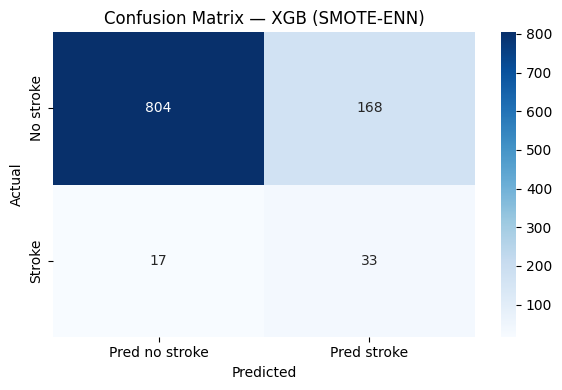

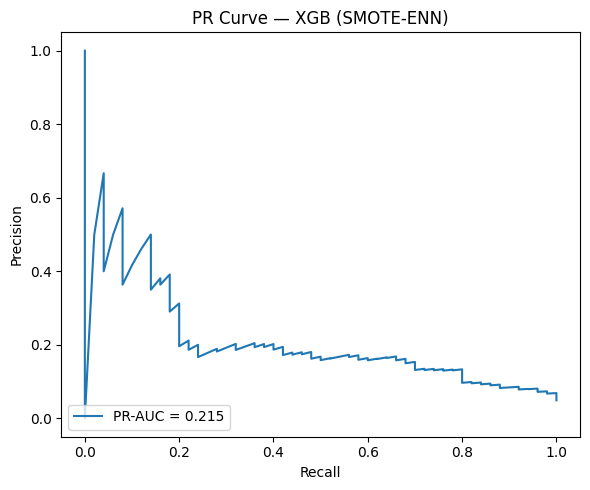

In [ ]:
# XGBoost — SMOTE-ENN
xgb_model = XGBClassifier(
    n_estimators=200,
    learning_rate=0.05,
    max_depth=4,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="binary:logistic",
    eval_metric="logloss",
    n_jobs=-1,
    random_state=42
)

xgb_model.fit(X_train_smoteenn, y_train_smoteenn)

y_pred = xgb_model.predict(X_test_scaled)
y_score = xgb_model.predict_proba(X_test_scaled)[:, 1]

print("=== XGBoost — SMOTE-ENN ===")
print(classification_report(y_test, y_pred))

acc    = accuracy_score(y_test, y_pred)
prec   = precision_score(y_test, y_pred, zero_division=0)
rec    = recall_score(y_test, y_pred, zero_division=0)
f1     = f1_score(y_test, y_pred, zero_division=0)
pr_auc = average_precision_score(y_test, y_score)

print("Accuracy :", acc)
print("Precision:", prec)
print("Recall   :", rec)
print("F1-score :", f1)
print("PR-AUC   :", pr_auc)

cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(6,4))
sns.heatmap(cm, annot=True, cmap="Blues", fmt="d",
            yticklabels=['No stroke', 'Stroke'],
            xticklabels=['Pred no stroke', 'Pred stroke'])
plt.title("Confusion Matrix — XGB (SMOTE-ENN)")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.tight_layout()
plt.show()

precision_curve, recall_curve, thresholds = precision_recall_curve(y_test, y_score)
plt.figure(figsize=(6,5))
plt.plot(recall_curve, precision_curve, label=f"PR-AUC = {pr_auc:.3f}")
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("PR Curve — XGB (SMOTE-ENN)")
plt.legend(loc="lower left")
plt.tight_layout()
plt.show()

results_list.append(["XGB", "SMOTE-ENN", acc, prec, rec, f1, pr_auc])

In [ ]:
df_results = pd.DataFrame(
    results_list,
    columns=["Model", "Resampling", "Accuracy", "Precision", "Recall", "F1", "PR_AUC"]
)

df_results


,Model,Resampling,Accuracy,Precision,Recall,F1,PR_AUC
0,LR,Original,0.951076,0.000000,0.00,0.000000,0.257129
1,LR,SMOTE,0.757339,0.141304,0.78,0.239264,0.265760
2,LR,SMOTE-ENN,0.717221,0.127726,0.82,0.221024,0.259409
3,SVM,Original,0.951076,0.000000,0.00,0.000000,0.095795
4,SVM,SMOTE,0.754403,0.134545,0.74,0.227692,0.211960
5,SVM,SMOTE-ENN,0.715264,0.122257,0.78,0.211382,0.207053
6,XGB,Original,0.951076,0.500000,0.04,0.074074,0.207306
7,XGB,SMOTE,0.889432,0.221239,0.50,0.306748,0.198759
